**SetUp & Explore**

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import re
import random
import os
from glob import glob

#############################################################
# Carregar e Explorar
#############################################################
def load_data(file_path: str): #, nrows=582000):
    data = pd.read_csv(file_path, delimiter=',')#, nrows=nrows)

    return data

Dados prévia da Amostra

In [20]:
file_path = '..\Caso_TAP\TAP_Previa\Amostra 1(DEP LIS).csv'
data_Amostra = load_data(file_path)

print("\n### Informações do Dataset ###\n")
print(data_Amostra.info())

print("\n### Descrição ###\n")
print(data_Amostra.describe(include='all'))
print(data_Amostra.shape)
print(data_Amostra.head(1))


### Informações do Dataset ###

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Flight Nr       156 non-null    object
 1   Dep Airport     156 non-null    object
 2   COD GATE DEP    156 non-null    object
 3   STAND_DEP       156 non-null    object
 4   Arr Airport     156 non-null    object
 5   STAND_ARR       156 non-null    object
 6   SCHD_DEP_DT     156 non-null    object
 7   SCHD_DEP_TM     156 non-null    object
 8   ACT_DEP_DT      156 non-null    object
 9   ACT_DEP_TM      156 non-null    object
 10  SCHD_ARR_DT     156 non-null    object
 11  SCHD_ARR_TM     156 non-null    object
 12  ACT_ARR_DT      156 non-null    object
 13  ACT_ARR_TM      156 non-null    object
 14  Sales Capacity  156 non-null    int64 
 15  NR_PAX          156 non-null    int64 
dtypes: int64(2), object(14)
memory usage: 19.6+ KB
None

### Descriçã

<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
C:\Users\joaoc\AppData\Local\Temp\ipykernel_10384\386520875.py:1: SyntaxWarning: invalid escape sequence '\C'
  file_path = '..\Caso_TAP\TAP_Previa\Amostra 1(DEP LIS).csv'


Dados do tempo de caminhada no hub do aeriporto

In [21]:
file_path = '..\Caso_TAP\TAP_Previa\Walking times HUB _ INFORM 1(Sheet1).csv'
data_Tempos_Caminnhada = load_data(file_path)

print("\n### Informações do Dataset ###\n")
print(data_Tempos_Caminnhada.info())

print("\n### Descrição ###\n")
print(data_Tempos_Caminnhada.describe(include='all'))
print(data_Tempos_Caminnhada.shape)
print(data_Tempos_Caminnhada.head(1))


### Informações do Dataset ###

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 6 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Traffic Network                    62 non-null     object 
 1   Start Traffic Network Point 1      62 non-null     object 
 2   Destination Traffic Network Point  62 non-null     object 
 3   Distance (in m)                    62 non-null     int64  
 4   Speed m/s                          62 non-null     float64
 5   Tempo minutos                      62 non-null     int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 3.0+ KB
None

### Descrição ###

           Traffic Network Start Traffic Network Point 1  \
count                   62                            62   
unique                   4                            21   
top     SCHENGEN-NSCHENGEN                         22-23   
freq                    18

<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
C:\Users\joaoc\AppData\Local\Temp\ipykernel_10384\3845097657.py:1: SyntaxWarning: invalid escape sequence '\C'
  file_path = '..\Caso_TAP\TAP_Previa\Walking times HUB _ INFORM 1(Sheet1).csv'


**Data Understanding**

**Hub walk Time**

Traffic Network        ->   NSCHENGEN-SCHENGEN  / Se omisso -> apaga

Start Traffic          ->   14-16               / Se omisso -> apaga
Network Point 1 

Destination Traffic    ->   150                 / Se omisso -> apaga
Network Point            

Distance (in m)        ->   7                   / Se omisso -> valor médio

Speed m/s              ->   1.1667              / Se omisso -> valor médio

Tempo minutos          ->   2                   / Se omisso -> valor médio

--------------------------/------------------------/---------------------/------------------

**Actual DATA**

*Temos dados de chegadas, partidas e escalas no aeroporto humberto delgado entre otubro de 2023 e janeiro de 2025*

**Arrival List**

Flight Nr        ->     TP 0008     / Se omisso -> apaga

Dep Airport      ->     NAT         / Se omisso -> apaga

STAND_DEP        ->     .           / Se . -> NaN

Arr Airport      ->     LIS         / Se omisso -> apaga

COD GATE ARR     ->     N           / Se omisso -> apaga

STAND_ARR        ->     803         / Se omisso -> apaga

SCHD_DEP_DT      ->     2023-10-01 00:00:00 / Se omisso -> apaga

SCHD_DEP_TM      ->     01:15               / Se omisso -> apaga

ACT_DEP_DT       ->     2023-10-01 00:00:00 / Se omisso -> apaga

ACT_DEP_TM       ->     01:01               / Se omisso -> apaga
 
SCHD_ARR_DT      ->     2023-10-01 00:00:00 / Se omisso -> apaga

SCHD_ARR_TM      ->     08:25               / Se omisso -> apaga

ACT_ARR_DT       ->     2023-10-01 00:00:00 / Se omisso -> apaga
 
ACT_ARR_TM       ->     07:51               / Se omisso -> apaga

Sales Capacity   ->     168                 / Se omisso -> moda

NR_PAX           ->     171                 / Se omisso, >Sales+5 -> apaga

Soma             ->     -34                 / Soma ?? 

--------------------------/------------------------/---------------------/------------------

**Connection List**

Pairing          ->     TP 1243 PRG - IAD TP 0233 / Se omisso -> apaga
    
NATIO            ->     AFG       / Se omisso -> apaga
    
IN_FLT_NR        ->     TP 1243   / Se omisso -> apaga
    
IN_BOARD_PNT     ->     PRG       / Se omisso -> apaga
    
IN_OFF_PNT       ->     LIS       / Se omisso -> apaga
    
IN_STD           ->     2024-02-29 00:00:00 / Se omisso -> apaga
    
OUT_STD,         ->     2024-03-01 00:00:00 / Se omisso -> apaga
    
OUT_FLT_NR       ->     TP 0233   / Se omisso -> apaga
    
OUT_BOARD_PNT    ->     LIS       / Se omisso -> apaga
     
OUT_OFF_PNT      ->     IAD       / Se omisso -> apaga
    
MISCONN          ->     0         / Se omisso -> apaga
    
SUCCESS_TRANSF   ->     1         / Se omisso -> apaga
    
PAX TRANSF       ->     1         / Se omisso -> apaga
    
CONNECTIVITY     ->     "100,00%" / Se omisso -> apaga 

--------------------------/------------------------/---------------------/------------------

**Departure List**

Flight Nr         ->       TP 0009       / Se omisso -> apaga

Dep Airport       ->       LIS           / Se omisso -> apaga

COD GATE DEP      ->       45B           / Se omisso -> apaga

STAND_DEP         ->       414           / Se omisso -> apaga
 
Arr Airport       ->       NAT           / Se omisso -> apaga

STAND_ARR         ->       .             / Se omisso -> apaga
 
SCHD_DEP_DT       ->       2024-03-01 00:00:00  / Se omisso -> apaga

SCHD_DEP_TM       ->       17:10                / Se omisso -> apaga

ACT_DEP_DT        ->       2024-03-01 00:00:00  / Se omisso -> apaga

ACT_DEP_TM        ->       17:24                / Se omisso -> apaga

SCHD_ARR_DT       ->       2024-03-02 00:00:00  / Se omisso -> apaga

SCHD_ARR_TM       ->       00:45                / Se omisso -> apaga

ACT_ARR_DT        ->       2024-03-02 00:00:00  / Se omisso -> apaga

ACT_ARR_TM        ->       01:09                / Se omisso -> apaga

Sales Capacity    ->       168                  / Se omisso -> apaga

NR_PAX            ->       128                  / Se omisso, >Sales+5 -> apaga


**Causas mais frequentes de atrasos de voo**

Condições Meteriológicas adversas (Vento de proa)

Controlo de Trafego Aéreo num aeroporto congestionado congestionado

Voo de Conexão (Espera por passageiros de outro voo atrasado)

Número elevado de passageiros (Passager Seat Bottle neck)

Reparações na aeronave

**Identificação de Voos Atrasados ou cancelados:**

Canceled Flight = SCHD_DEP_DT != ACT_DEP_DT 

Delayed Flight  = SCHD_DEP_TM < ACT_DEP_TM 

**Precisamos definir o tempo antes da previsão do modelo**

Queremos saber problemas internos ou externos é companhia aerea?
Quais os principais componentes que influenciam?
Qual informação é que temos?
Quais são os dados mais importantes


In [22]:
caminho_dos_ARRLIS = '../Caso_TAP/TAP 3 1/ISCTE/ARRLIS'  
arquivos_csv_ARRLIS = glob(os.path.join(caminho_dos_ARRLIS, "*.csv"))

dataframes_ARRLIS = []

# Ler e adicionar cada CSV à lista
for arquivo in arquivos_csv_ARRLIS:
    df_ARRLIS = pd.read_csv(arquivo)
    dataframes_ARRLIS.append(df_ARRLIS)
    
df_final_ARRLIS = pd.concat(dataframes_ARRLIS, ignore_index=True)

df_final_ARRLIS.to_csv("dados_combinados_ARRLIS.csv", index=False)

In [23]:
#problema no ficheiro CONNECTLIS_25oct23_01nov23

caminho_dos_CONNECTLIS = '../Caso_TAP/TAP 3 1/ISCTE/CONNECTLIS'  
arquivos_csv_CONNECTLIS = glob(os.path.join(caminho_dos_CONNECTLIS, "*.csv"))

dataframes_CONNECTLIS = []

for arquivo in arquivos_csv_CONNECTLIS:
    df_CONNLIS = pd.read_csv(arquivo, sep=',', quotechar='"', encoding='utf-8', engine='python') 
    dataframes_CONNECTLIS.append(df_CONNLIS)
    
df_final_CONNECTLIS = pd.concat(dataframes_CONNECTLIS, ignore_index=True)

for linha in df_final_CONNECTLIS:
    linha = linha.replace('""', '"')

df_final_CONNECTLIS.to_csv("dados_combinados_CONNECTLIS.csv", index=False)

In [24]:
caminho_dos_DEPLIS = '../Caso_TAP/TAP 3 1/ISCTE/DEPLIS'  
arquivos_csv_DEPLIS = glob(os.path.join(caminho_dos_DEPLIS, "*.csv"))

dataframes_DEPLIS = []

for arquivo in arquivos_csv_DEPLIS:
    df_DEPLIS = pd.read_csv(arquivo)  # Se houver separador diferente, use sep=";"
    dataframes_DEPLIS.append(df_DEPLIS)
    
df_final_DEPLIS = pd.concat(dataframes_DEPLIS, ignore_index=True)

df_final_DEPLIS.to_csv("dados_combinados_DEPLIS.csv", index=False)

In [25]:
# Mostrar as primeiras linhas do dataframe final
print("\n Dados de chegada ao Aeroporto \n")
print(df_final_ARRLIS.head())
print("\n Dados de conexão no Aeroporto \n")
print(df_final_CONNECTLIS.head())
print("\n Dados de partida do Aeroporto \n")
print(df_final_DEPLIS.head())


 Dados de chegada ao Aeroporto 

  Flight Nr Dep Airport STAND_DEP Arr Airport COD GATE ARR STAND_ARR  \
0   TP 0008         NAT         .         LIS            N       803   
1   TP 0012         REC         .         LIS            N       404   
2   TP 0022         SSA         .         LIS           43       143   
3   TP 0036         FOR         .         LIS            N       602   
4   TP 0048         BEL         .         LIS            N       607   

           SCHD_DEP_DT SCHD_DEP_TM           ACT_DEP_DT ACT_DEP_TM  \
0  2023-10-01 00:00:00       01:15  2023-10-01 00:00:00      01:01   
1  2023-10-01 00:00:00       01:20  2023-10-01 00:00:00      01:45   
2  2023-10-01 00:00:00       01:55  2023-10-01 00:00:00      02:08   
3  2023-10-01 00:00:00       01:40  2023-10-01 00:00:00      01:37   
4  2023-10-01 00:00:00       02:35  2023-10-01 00:00:00      02:22   

           SCHD_ARR_DT SCHD_ARR_TM           ACT_ARR_DT ACT_ARR_TM  \
0  2023-10-01 00:00:00       08:25  2023-1

**DATA Understanding**

In [26]:
# Configurações de exibição
pd.set_option('display.max_columns', None)
sns.set(style="whitegrid")

# 1. Carregar os dados
# Substitua 'seus_dados.csv' pelo caminho do seu arquivo de dados
df_ARRLIS = df_final_ARRLIS
df_CONNECTLIS = df_final_CONNECTLIS
df_DEPLIS = df_final_DEPLIS

# 2. Conversão de tipos de dados

df_ARRLIS['SCHD_DEP_DT'] = pd.to_datetime(df_ARRLIS['SCHD_DEP_DT'] + ' ' + df_ARRLIS['SCHD_DEP_TM'])
df_ARRLIS['ACT_DEP_DT'] = pd.to_datetime(df_ARRLIS['ACT_DEP_DT'] + ' ' + df_ARRLIS['ACT_DEP_TM'])
df_ARRLIS['SCHD_ARR_DT'] = pd.to_datetime(df_ARRLIS['SCHD_ARR_DT'] + ' ' + df_ARRLIS['SCHD_ARR_TM'])
df_ARRLIS['ACT_ARR_DT'] = pd.to_datetime(df_ARRLIS['ACT_ARR_DT'] + ' ' + df_ARRLIS['ACT_ARR_TM'])


# 3. Cálculo de atrasos
df_ARRLIS['Atraso_Partida'] = (df_ARRLIS['ACT_DEP_DT'] - df_ARRLIS['SCHD_DEP_DT']).dt.total_seconds() / 60.0
df_ARRLIS['Atraso_Chegada'] = (df_ARRLIS['ACT_ARR_DT'] - df_ARRLIS['SCHD_ARR_DT']).dt.total_seconds() / 60.0


df_CONNECTLIS['IN_STD'] = pd.to_datetime(df_CONNECTLIS['IN_STD'])
df_CONNECTLIS['OUT_STD'] = pd.to_datetime(df_CONNECTLIS['OUT_STD'])

# Convertendo colunas de data e hora para datetime
df_DEPLIS['SCHD_DEP_DT'] = pd.to_datetime(df_DEPLIS['SCHD_DEP_DT'] + ' ' + df_DEPLIS['SCHD_DEP_TM'])
df_DEPLIS['ACT_DEP_DT'] = pd.to_datetime(df_DEPLIS['ACT_DEP_DT'] + ' ' + df_DEPLIS['ACT_DEP_TM'])
df_DEPLIS['SCHD_ARR_DT'] = pd.to_datetime(df_DEPLIS['SCHD_ARR_DT'] + ' ' + df_DEPLIS['SCHD_ARR_TM'])
df_DEPLIS['ACT_ARR_DT'] = pd.to_datetime(df_DEPLIS['ACT_ARR_DT'] + ' ' + df_DEPLIS['ACT_ARR_TM'])


# 3. Cálculo de atrasos de saida do Aeroporto LIS
df_DEPLIS['Atraso_Partida'] = (df_DEPLIS['ACT_DEP_DT'] - df_DEPLIS['SCHD_DEP_DT']).dt.total_seconds() / 60.0
df_DEPLIS['Atraso_Chegada'] = (df_DEPLIS['ACT_ARR_DT'] - df_DEPLIS['SCHD_ARR_DT']).dt.total_seconds() / 60.0

# de entrada no aeroporto de LIS
df_ARRLIS['Atraso_Partida'] = (df_ARRLIS['ACT_DEP_DT'] - df_ARRLIS['SCHD_DEP_DT']).dt.total_seconds() / 60.0
df_ARRLIS['Atraso_Chegada'] = (df_ARRLIS['ACT_ARR_DT'] - df_ARRLIS['SCHD_ARR_DT']).dt.total_seconds() / 60.0

C:\Users\joaoc\AppData\Local\Temp\ipykernel_10384\3160680427.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_ARRLIS['SCHD_DEP_DT'] = pd.to_datetime(df_ARRLIS['SCHD_DEP_DT'] + ' ' + df_ARRLIS['SCHD_DEP_TM'])
C:\Users\joaoc\AppData\Local\Temp\ipykernel_10384\3160680427.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_ARRLIS['ACT_DEP_DT'] = pd.to_datetime(df_ARRLIS['ACT_DEP_DT'] + ' ' + df_ARRLIS['ACT_DEP_TM'])
C:\Users\joaoc\AppData\Local\Temp\ipykernel_10384\3160680427.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_ARRLIS['SCHD_ARR_DT'] = pd.to_dateti

In [27]:
# Função para verificar valores nulos por coluna em qualquer DataFrame
def verificar_nulos(df, nome_df):
    print(f"\nDados omissos em {nome_df}:")
    print(df.isnull().sum().sort_values(ascending=False))

# Verificando para os três DataFrames
verificar_nulos(df_ARRLIS, "ARRLIS")
verificar_nulos(df_CONNECTLIS, "CONNLIS")
verificar_nulos(df_DEPLIS, "DEPLIS")



Dados omissos em ARRLIS:
Flight Nr                      0
Dep Airport                    0
STAND_DEP                      0
Arr Airport                    0
COD GATE ARR                   0
STAND_ARR                      0
SCHD_DEP_DT                    0
SCHD_DEP_TM                    0
ACT_DEP_DT                     0
ACT_DEP_TM                     0
SCHD_ARR_DT                    0
SCHD_ARR_TM                    0
ACT_ARR_DT                     0
ACT_ARR_TM                     0
Sales Capacity                 0
NR_PAX                         0
Soma de ARR_DLY_TM_SCHD_ACT    0
Atraso_Partida                 0
Atraso_Chegada                 0
dtype: int64

Dados omissos em CONNLIS:
Pairing           0
NATIO             0
IN_FLT_NR         0
IN_BOARD_PNT      0
IN_OFF_PNT        0
IN_STD            0
OUT_STD           0
OUT_FLT_NR        0
OUT_BOARD_PNT     0
OUT_OFF_PNT       0
MISCONN           0
SUCCESS_TRANSF    0
PAX TRANSF        0
CONNECTIVITY      0
dtype: int64

Dados omissos

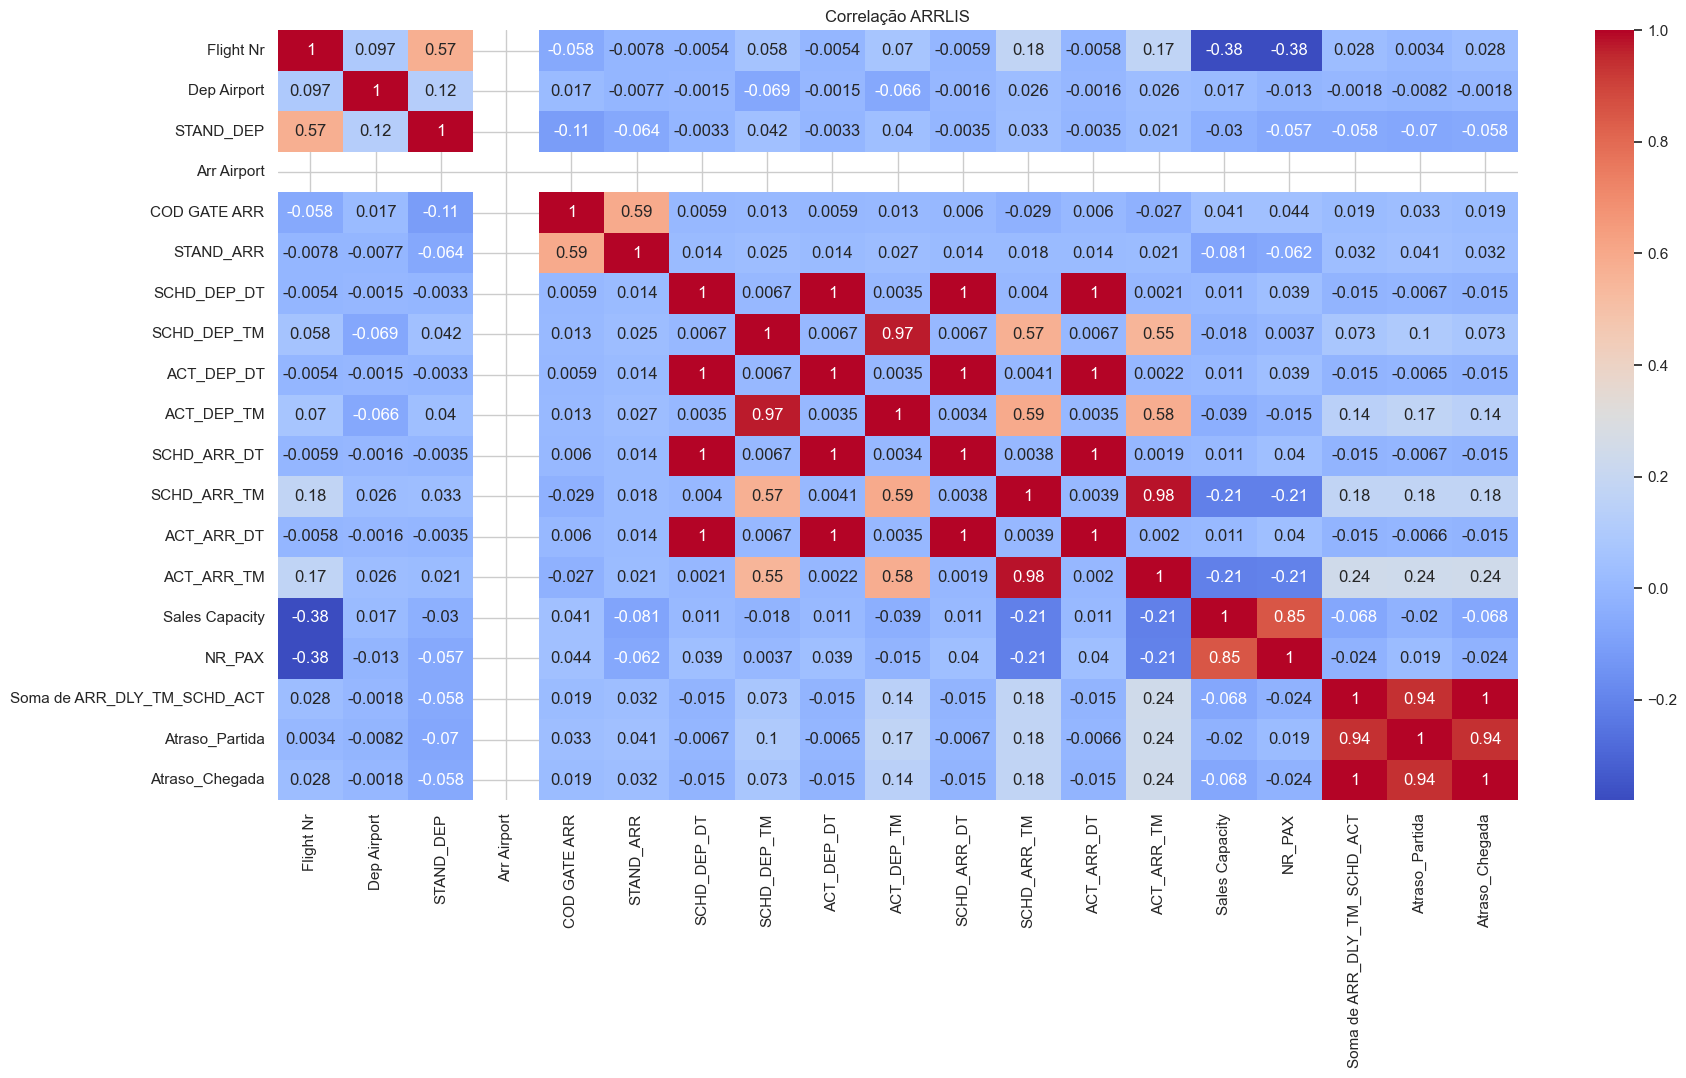

In [28]:
from sklearn.preprocessing import LabelEncoder

df_corr = df_ARRLIS.copy()

label_cols = df_corr.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in label_cols:
    try:
        df_corr[col] = le.fit_transform(df_corr[col])
    except:
        df_corr[col] = df_corr[col].astype(str).apply(lambda x: hash(x) % 1000)

plt.figure(figsize=(20, 10))
sns.heatmap(df_corr[:].corr(), annot=True, cmap='coolwarm')
plt.title("Correlação ARRLIS")
plt.show()


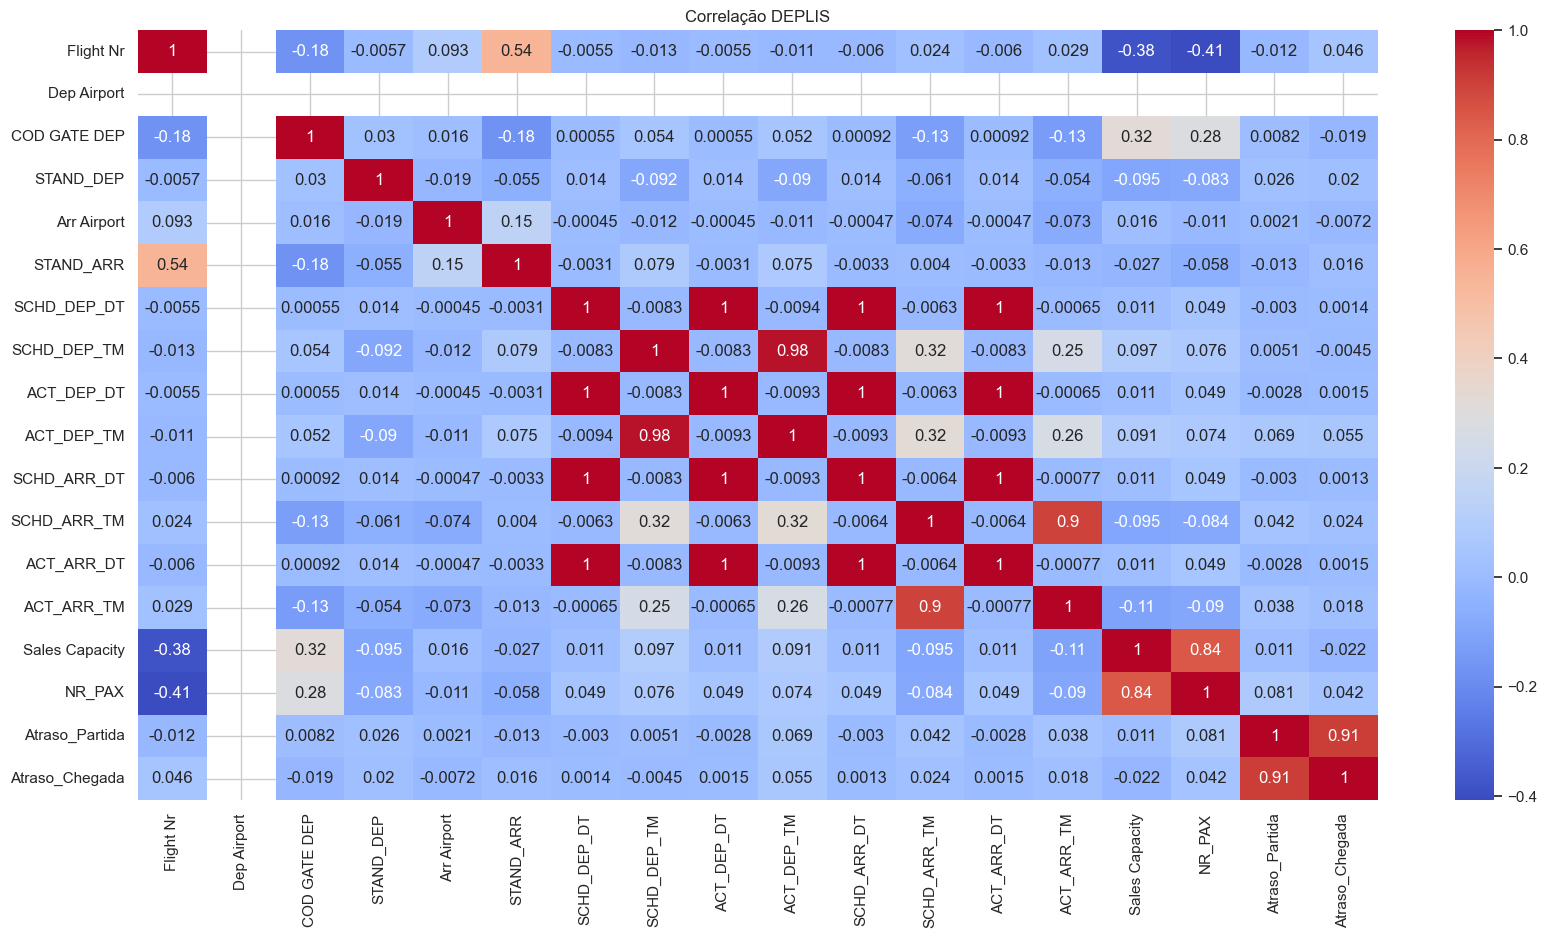

In [29]:
from sklearn.preprocessing import LabelEncoder

df_corr = df_DEPLIS.copy()

label_cols = df_corr.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in label_cols:
    try:
        df_corr[col] = le.fit_transform(df_corr[col])
    except:
        df_corr[col] = df_corr[col].astype(str).apply(lambda x: hash(x) % 1000)

plt.figure(figsize=(20, 10))
sns.heatmap(df_corr[:].corr(), annot=True, cmap='coolwarm')
plt.title("Correlação DEPLIS")
plt.show()

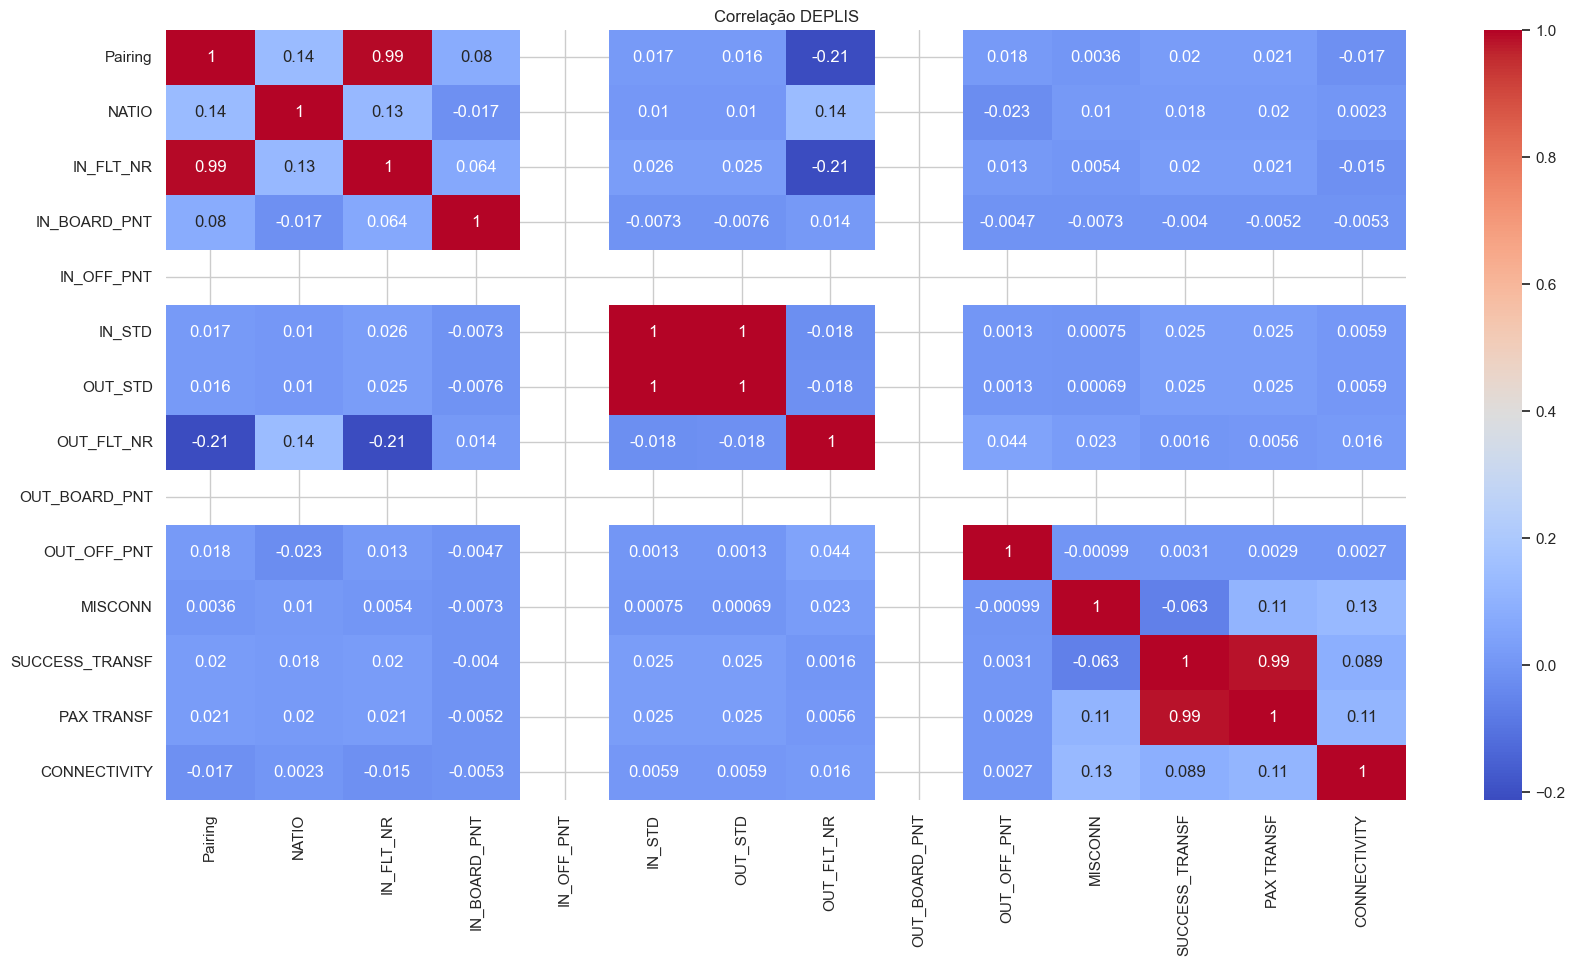

In [30]:
from sklearn.preprocessing import LabelEncoder

df_corr = df_CONNECTLIS.copy()

label_cols = df_corr.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in label_cols:
    try:
        df_corr[col] = le.fit_transform(df_corr[col])
    except:
        df_corr[col] = df_corr[col].astype(str).apply(lambda x: hash(x) % 1000)

plt.figure(figsize=(20, 10))
sns.heatmap(df_corr[:].corr(), annot=True, cmap='coolwarm')
plt.title("Correlação DEPLIS")
plt.show()

C:\Users\joaoc\AppData\Local\Temp\ipykernel_10384\3825983935.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  misconn_df['Mês_Operação'] = misconn_df['IN_STD'].dt.to_period('M').astype(str)


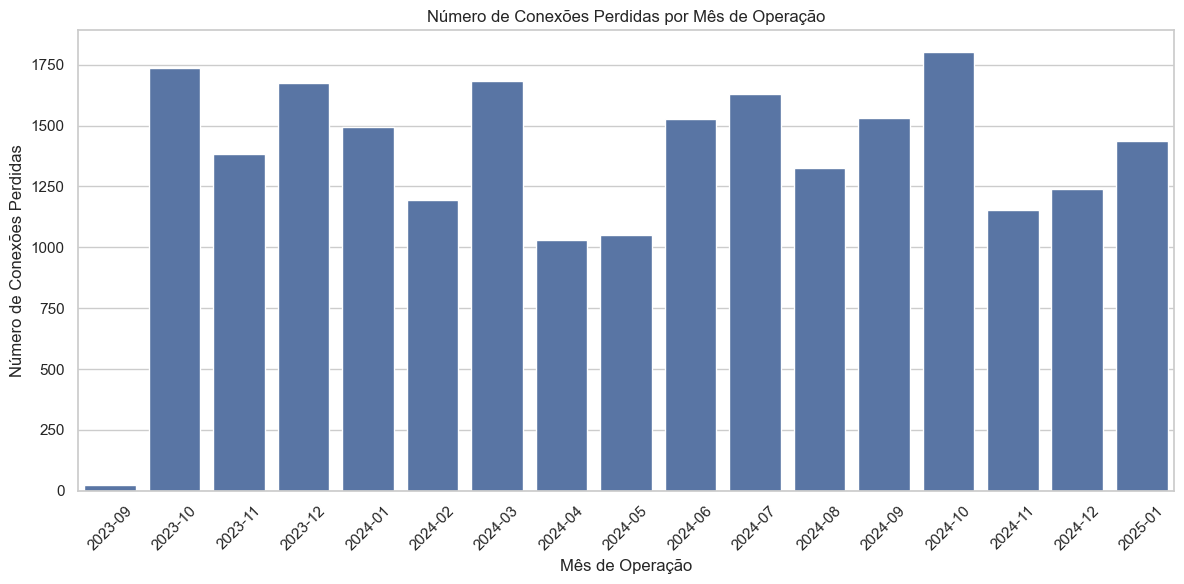

In [31]:
misconn_df = df_CONNECTLIS[df_CONNECTLIS['MISCONN'] == 1]
misconn_df['Mês_Operação'] = misconn_df['IN_STD'].dt.to_period('M').astype(str)
misconn_df = misconn_df.sort_values(by='IN_STD')

# Plot
plt.figure(figsize=(12, 6))
sns.countplot(x='Mês_Operação', data=misconn_df, order=misconn_df['Mês_Operação'].value_counts().sort_index().index)
plt.title('Número de Conexões Perdidas por Mês de Operação')
plt.xlabel('Mês de Operação')
plt.ylabel('Número de Conexões Perdidas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

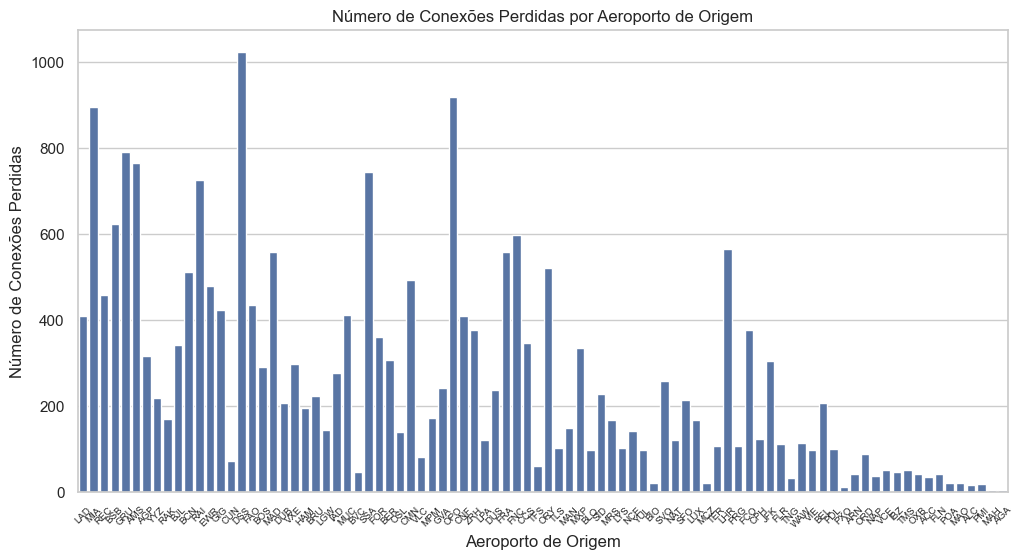

In [32]:
misconn_df = df_CONNECTLIS[df_CONNECTLIS['MISCONN'] == 1]

plt.figure(figsize=(12, 6))
sns.countplot(x='IN_BOARD_PNT', data=misconn_df)
plt.title('Número de Conexões Perdidas por Aeroporto de Origem')
plt.xlabel('Aeroporto de Origem')
plt.ylabel('Número de Conexões Perdidas')
plt.xticks(rotation=45, fontsize = 7)
plt.show()

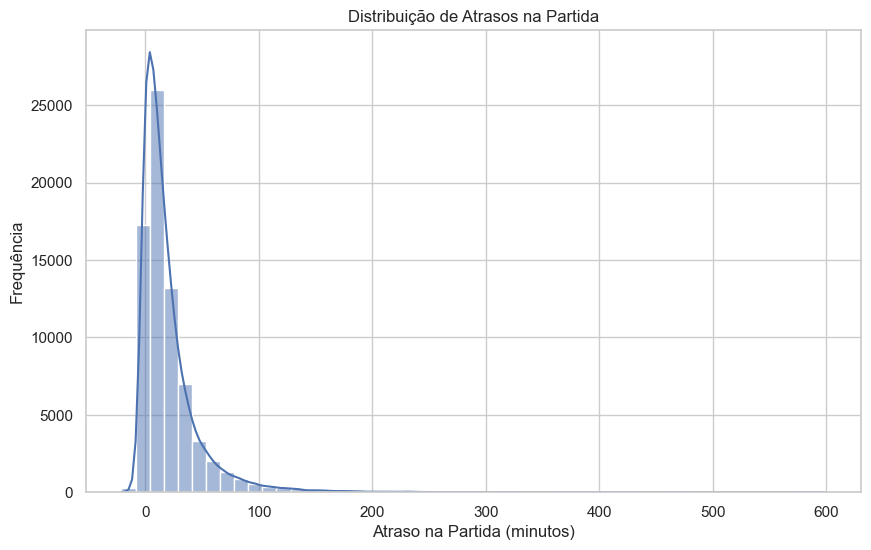

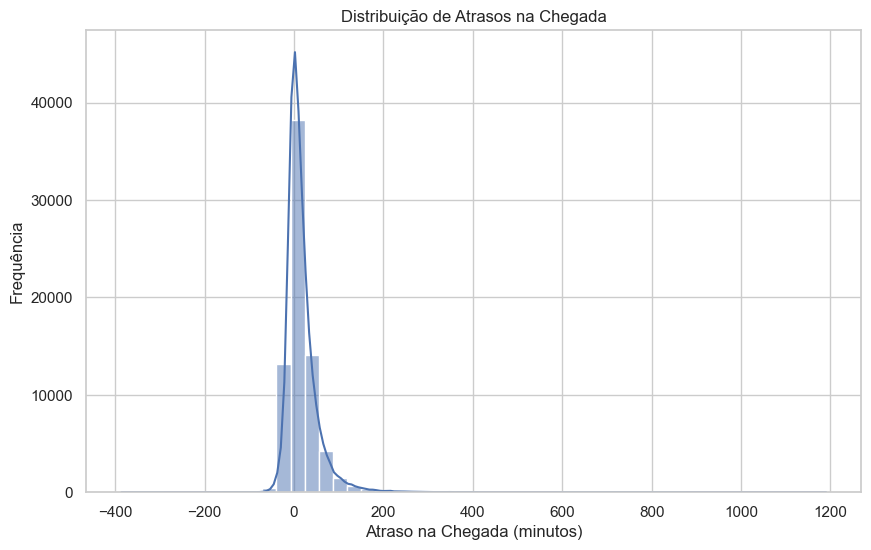

In [33]:
# Algumas Visualizações

# Distribuição de atrasos na partida
plt.figure(figsize=(10, 6))
sns.histplot(df_DEPLIS['Atraso_Partida'].dropna(), bins=50, kde=True)
plt.title('Distribuição de Atrasos na Partida')
plt.xlabel('Atraso na Partida (minutos)')
plt.ylabel('Frequência')
plt.show()

# Distribuição de atrasos na chegada
plt.figure(figsize=(10, 6))
sns.histplot(df_ARRLIS['Atraso_Chegada'].dropna(), bins=50, kde=True)
plt.title('Distribuição de Atrasos na Chegada')
plt.xlabel('Atraso na Chegada (minutos)')
plt.ylabel('Frequência')
plt.show()

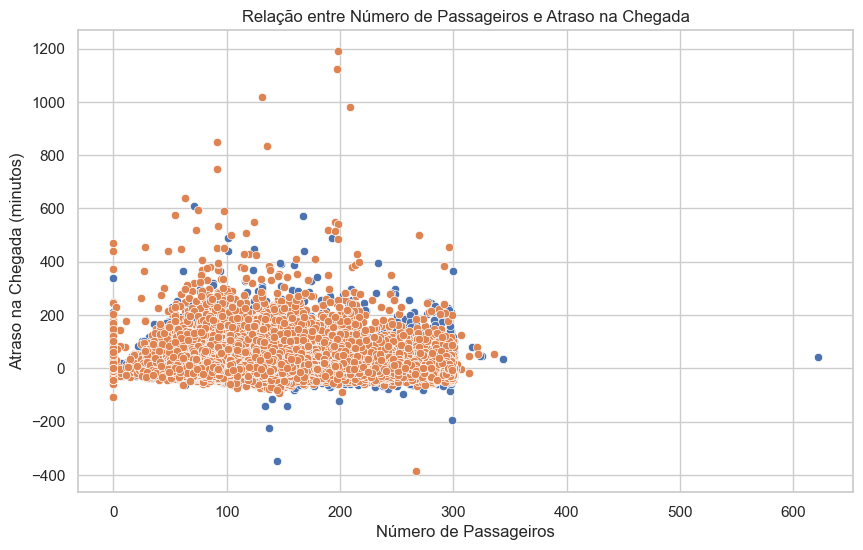

In [34]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='NR_PAX', y='Atraso_Chegada', data=df_final_DEPLIS)
sns.scatterplot(x='NR_PAX', y='Atraso_Chegada', data= df_final_ARRLIS )
plt.title('Relação entre Número de Passageiros e Atraso na Chegada')
plt.xlabel('Número de Passageiros')
plt.ylabel('Atraso na Chegada (minutos)')
plt.show()